# Probabilidad: dependencia estadística, probabilidad condicional y teorema de Bayes

Desarrollo de los ejercicios sobre probabilidades en condiciones de dependencia estadística,
teorema de Bayes e independencia estadística. El tratamiento se apoya en la probabilidad condicional,
la regla de la probabilidad total y la formulación de Bayes sobre particiones del espacio muestral.
Los cálculos se resuelven en Python sobre espacios muestrales finitos y se contrastan por simulación
Monte Carlo con semilla fija; las distribuciones conjuntas se verifican por normalización.

## Marco teórico

### Probabilidad condicional

Para eventos con $P(B) > 0$, la probabilidad de $A$ condicionada a la ocurrencia de $B$ es

$$P(A|B) = \frac{P(A \cap B)}{P(B)}, \qquad P(B) > 0$$

o bien, en forma multiplicativa, $P(A \cap B) = P(A|B)\,P(B)$. El condicionamiento descarta los
resultados fuera de $B$: el espacio muestral efectivo pasa a ser $B$ con probabilidad 1 y los
resultados que no pertenecen a $B$ quedan con probabilidad cero.

### Independencia estadística

Dos eventos $A$ y $B$ son independientes cuando

$$P(A \cap B) = P(A)\,P(B)$$

y para $P(B) > 0$ esto equivale a $P(A|B) = P(A)$: conocer la ocurrencia de $B$ no modifica la
probabilidad de $A$. La verificación requiere probabilidades marginales definidas y evento de
referencia con probabilidad positiva.

La independencia no se confunde con la exclusión mutua. Si $A \cap B = \varnothing$ con
$P(A) > 0$ y $P(B) > 0$, entonces $P(A \cap B) = 0 < P(A)P(B)$: eventos excluyentes con probabilidad
positiva nunca son independientes.

### Reglas operativas bajo dependencia

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

$$A^c \cap B^c = (A \cup B)^c \quad \Rightarrow \quad P(A^c \cap B^c) = 1 - P(A \cup B)$$

$$A^c \cap B = B - (A \cap B) \quad \Rightarrow \quad P(A^c \cap B) = P(B) - P(A \cap B)$$

### Probabilidad total y teorema de Bayes

Sea $\{A_1, \dots, A_n\}$ una partición del espacio muestral: eventos mutuamente excluyentes y
exhaustivos con $P(A_i) > 0$. Para cualquier evento $B$ con $P(B) > 0$:

$$P(B) = \sum_{i} P(A_i)\,P(B|A_i) \qquad \text{(regla de la probabilidad total)}$$

$$P(A_i|B) = \frac{P(A_i)\,P(B|A_i)}{\sum_{j} P(A_j)\,P(B|A_j)} \qquad \text{(teorema de Bayes)}$$

En el caso de dos hipótesis complementarias $H$ y $H^c$:

$$P(B) = P(H)\,P(B|H) + P(H^c)\,P(B|H^c)$$

Supuestos: la partición cubre todos los resultados posibles sin traslapes, cada $P(A_i) > 0$ y
$P(B) > 0$. El numerador de Bayes es la probabilidad conjunta entre la hipótesis y la evidencia; el
denominador normaliza de modo que las probabilidades condicionales sobre la partición sumen 1.

In [33]:
import itertools
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

print("numpy", np.__version__, "| matplotlib", mpl.__version__)

numpy 2.5.4 | matplotlib 3.11.2


## 1. Dos dados equilibrados

### a) Espacio muestral

Cada dado presenta seis resultados y se suponen equilibrados e independientes entre sí, de modo que
el resultado de una tirada no altera la del otro. Por el principio multiplicativo el espacio muestral
es

$$S = \{(i, j) : i, j \in \{1, 2, 3, 4, 5, 6\}\}, \qquad |S| = 6 \cdot 6 = 36$$

Los 36 pares son equiprobables con probabilidad $1/36 \approx 0.0278$ cada uno. Supuestos: dados sin
sesgo, caras independientes y observación del par ordenado (primero el primer dado, después el
segundo), de modo que $(1, 3)$ y $(3, 1)$ son resultados distintos.

In [34]:
S = list(itertools.product(range(1, 7), repeat=2))

print("|S| =", len(S), "| probabilidad de cada par:", round(1 / len(S), 4))
print("primeros pares:", S[:4])
print("pares que suman 4:", [p for p in S if sum(p) == 4])

|S| = 36 | probabilidad de cada par: 0.0278
primeros pares: [(1, 1), (1, 2), (1, 3), (1, 4)]
pares que suman 4: [(1, 3), (2, 2), (3, 1)]


### b) Eventos $A$ y $B$

$A$ = la suma de ambos resultados es 4, $B$ = al menos uno de los resultados es 3.

i. $A = \{(1,3),\ (2,2),\ (3,1)\}$, tres pares:

$$P(A) = \frac{3}{36} = \frac{1}{12} \approx 0.0833$$

ii. $B$ contiene los 6 pares con el primer dado en 3 y los 6 con el segundo dado en 3, contando una
sola vez $(3,3)$: $6 + 6 - 1 = 11$ pares.

$$P(B) = \frac{11}{36} \approx 0.3056$$

iii. $A \cap B$ exige suma 4 y presencia de un 3: se cumplen $(1,3)$ y $(3,1)$; $(2,2)$ suma 4 pero
no tiene un 3.

$$P(A \cap B) = \frac{2}{36} = \frac{1}{18} \approx 0.0556$$

iv. Por la regla de inclusión y exclusión:

$$P(A \cup B) = P(A) + P(B) - P(A \cap B) = \frac{3}{36} + \frac{11}{36} - \frac{2}{36} = \frac{12}{36} = \frac{1}{3} \approx 0.3333$$

v. Por las leyes de De Morgan, $A^c \cap B^c = (A \cup B)^c$:

$$P(A^c \cap B^c) = 1 - P(A \cup B) = 1 - \frac{1}{3} = \frac{2}{3} \approx 0.6667$$

vi. El evento $A^c \cap B$ son los pares de $B$ que no están en $A$:

$$P(A^c \cap B) = P(B) - P(A \cap B) = \frac{11}{36} - \frac{2}{36} = \frac{9}{36} = \frac{1}{4} = 0.25$$

Los seis valores se obtienen abajo por enumeración directa de $S$ y se contrastan con simulación.

In [35]:
A = {p for p in S if sum(p) == 4}
B = {p for p in S if 3 in p}
AB = A & B
AuB = A | B
AcBc = set(S) - AuB
AcB = B - A

eventos = [
    ("P(A)", A),
    ("P(B)", B),
    ("P(A intersección B)", AB),
    ("P(A unión B)", AuB),
    ("P(Ac intersección Bc)", AcBc),
    ("P(Ac intersección B)", AcB),
]

print(f"{'evento':<24}{'|ev|':>5}   probabilidad")
for nombre, ev in eventos:
    print(f"{nombre:<24}{len(ev):5d}   {len(ev):2d}/36 = {len(ev)/36:.4f}")

# verificación por simulación de las tres probabilidades base
rng = np.random.default_rng(3)
n_sim = 100_000
d1 = rng.integers(1, 7, n_sim)
d2 = rng.integers(1, 7, n_sim)
en_a = (d1 + d2) == 4
en_b = (d1 == 3) | (d2 == 3)

print("\nsimulación con M = 100 000 tiradas")
print("P(A)     teórica 0.0833 | simulada", round(en_a.mean(), 4))
print("P(B)     teórica 0.3056 | simulada", round(en_b.mean(), 4))
print("P(A y B) teórica 0.0556 | simulada", round((en_a & en_b).mean(), 4))

evento                   |ev|   probabilidad
P(A)                        3    3/36 = 0.0833
P(B)                       11   11/36 = 0.3056
P(A intersección B)         2    2/36 = 0.0556
P(A unión B)               12   12/36 = 0.3333
P(Ac intersección Bc)      24   24/36 = 0.6667
P(Ac intersección B)        9    9/36 = 0.2500

simulación con M = 100 000 tiradas
P(A)     teórica 0.0833 | simulada 0.0822
P(B)     teórica 0.3056 | simulada 0.3055
P(A y B) teórica 0.0556 | simulada 0.0549


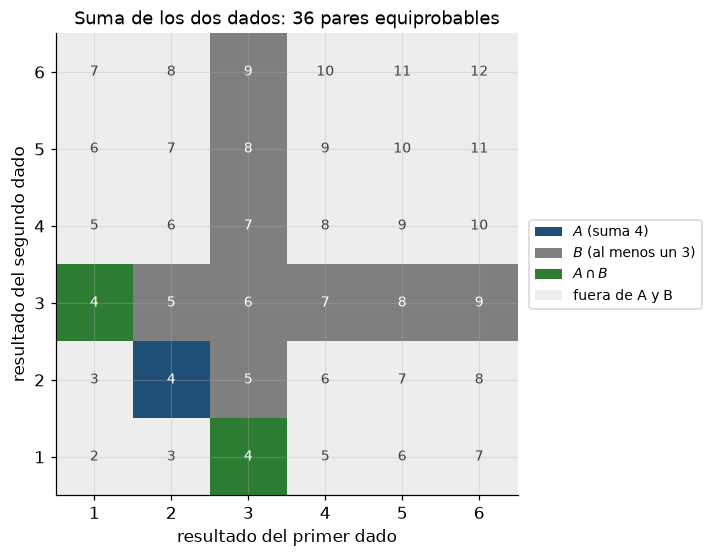

In [20]:
rgb = np.full((6, 6, 3), 0.93)
for i in range(6):          # i: resultado del segundo dado (fila)
    for j in range(6):      # j: resultado del primer dado (columna)
        par = (j + 1, i + 1)
        en_a, en_b = par in A, par in B
        if en_a and en_b:
            rgb[i, j] = (0.18, 0.49, 0.20)
        elif en_a:
            rgb[i, j] = (0.12, 0.31, 0.47)
        elif en_b:
            rgb[i, j] = (0.50, 0.50, 0.50)

fig, ax = plt.subplots(figsize=(9.6, 5.2))
ax.imshow(rgb, origin="lower", extent=(0.5, 6.5, 0.5, 6.5), interpolation="nearest")
for i in range(6):
    for j in range(6):
        par = (j + 1, i + 1)
        marcado = (par in A) or (par in B)
        ax.text(j + 1, i + 1, str(sum(par)), ha="center", va="center", fontsize=9,
                color="white" if marcado else "#404040")

ax.set_xticks(range(1, 7))
ax.set_yticks(range(1, 7))
ax.set_xlabel("resultado del primer dado")
ax.set_ylabel("resultado del segundo dado")
ax.set_title("Suma de los dos dados: 36 pares equiprobables")
ax.legend(handles=[
    Patch(facecolor=AZUL, label=r"$A$ (suma 4)"),
    Patch(facecolor=GRIS, label=r"$B$ (al menos un 3)"),
    Patch(facecolor=VERDE, label=r"$A \cap B$"),
    Patch(facecolor="#ededed", label="fuera de A y B"),
], fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(rect=(0, 0, 0.80, 1))
plt.show()

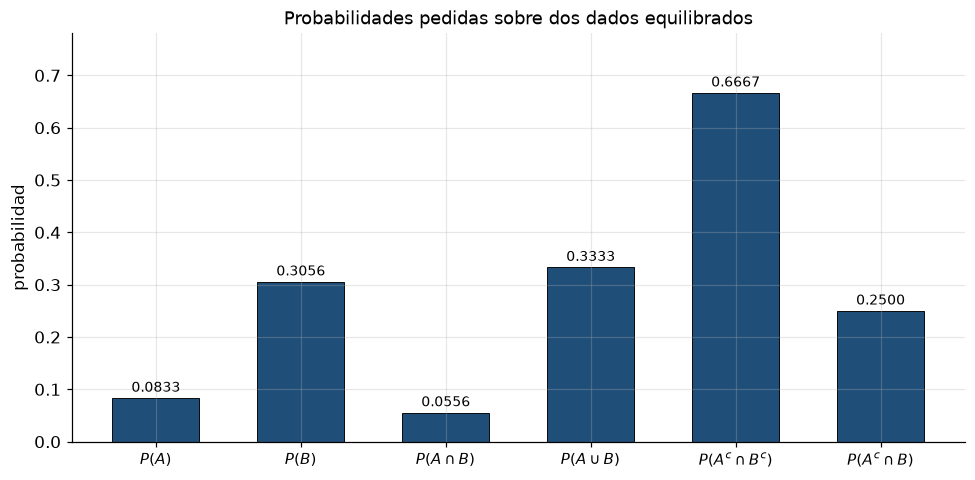

In [21]:
nombres = [r"$P(A)$", r"$P(B)$", r"$P(A \cap B)$", r"$P(A \cup B)$",
           r"$P(A^c \cap B^c)$", r"$P(A^c \cap B)$"]
valores = [len(ev) / 36 for _, ev in eventos]

fig, ax = plt.subplots()
ax.bar(range(6), valores, width=0.6, color=AZUL, edgecolor="black", linewidth=0.6)
for i, v in enumerate(valores):
    ax.text(i, v + 0.012, f"{v:.4f}", ha="center", fontsize=9)
ax.set_xticks(range(6))
ax.set_xticklabels(nombres, fontsize=10)
ax.set_ylabel("probabilidad")
ax.set_ylim(0, 0.78)
ax.set_title("Probabilidades pedidas sobre dos dados equilibrados")
plt.tight_layout()
plt.show()

## 2. Espacio muestral discreto y probabilidad condicional

Datos: $S = \{0, 1, 2, \dots, 11\}$ con 12 resultados equiprobables (probabilidad $1/12$ cada uno),
$A = \{2,3,4,5,6\}$ y $B = \{6,7,8,9\}$. La notación $P(A/B)$ del enunciado corresponde a la
probabilidad condicional estándar $P(A|B)$.

i. $A$ tiene 5 elementos:

$$P(A) = \frac{5}{12} \approx 0.4167$$

ii. $B$ tiene 4 elementos:

$$P(B) = \frac{4}{12} = \frac{1}{3} \approx 0.3333$$

iii. $A \cap B = \{6\}$, único elemento común:

$$P(A \cap B) = \frac{1}{12} \approx 0.0833$$

iv. Aplicando la definición de probabilidad condicional:

$$P(A|B) = \frac{P(A \cap B)}{P(B)} = \frac{1/12}{4/12} = \frac{1}{4} = 0.25$$

v. Del mismo modo, condicionando sobre $A$:

$$P(B|A) = \frac{P(A \cap B)}{P(A)} = \frac{1/12}{5/12} = \frac{1}{5} = 0.20$$

$P(A|B) = 0.25 \ne P(A) = 0.4167$ y $P(B|A) = 0.20 \ne P(B) = 0.3333$: conocer un evento modifica
la probabilidad del otro, de modo que $A$ y $B$ son dependientes.

Supuestos: distribución uniforme sobre $S$, $P(A) > 0$ y $P(B) > 0$ para que el condicionamiento
esté definido.

In [22]:
S2 = set(range(12))
A2 = {2, 3, 4, 5, 6}
B2 = {6, 7, 8, 9}

p_a = len(A2) / len(S2)
p_b = len(B2) / len(S2)
p_ab = len(A2 & B2) / len(S2)

print(f"P(A)                = {len(A2)}/12 = {p_a:.4f}")
print(f"P(B)                = {len(B2)}/12 = {p_b:.4f}")
print(f"P(A intersección B) = {len(A2 & B2)}/12 = {p_ab:.4f}")
print(f"P(A|B) = P(A y B) / P(B) = {p_ab / p_b:.4f}")
print(f"P(B|A) = P(A y B) / P(A) = {p_ab / p_a:.4f}")
print("independientes:", math.isclose(p_ab / p_b, p_a) and math.isclose(p_ab / p_a, p_b))

P(A)                = 5/12 = 0.4167
P(B)                = 4/12 = 0.3333
P(A intersección B) = 1/12 = 0.0833
P(A|B) = P(A y B) / P(B) = 0.2500
P(B|A) = P(A y B) / P(A) = 0.2000
independientes: False


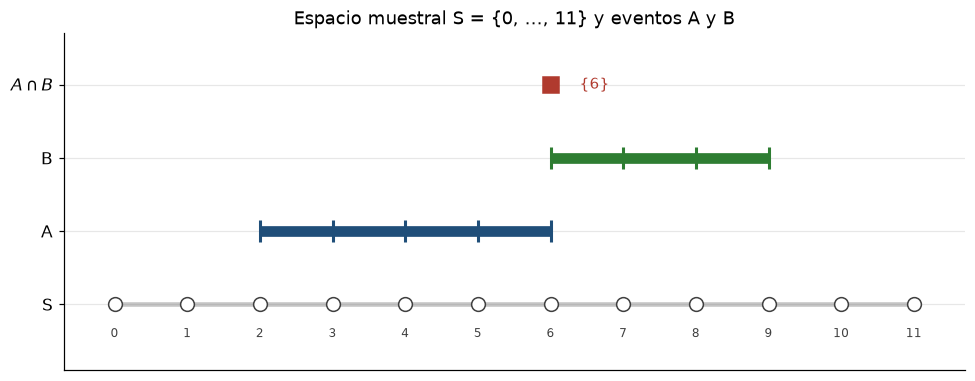

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.6))

ax.hlines(0, 0, 11, color=GRIS, linewidth=3, alpha=0.45)
for x in sorted(S2):
    ax.plot(x, 0, "o", color="white", markeredgecolor="#404040", markersize=9, zorder=3)
    ax.text(x, -0.45, str(x), ha="center", fontsize=8, color="#404040")

ax.hlines(1, min(A2), max(A2), color=AZUL, linewidth=7)
for x in sorted(A2):
    ax.plot(x, 1, "|", color=AZUL, markersize=15, markeredgewidth=2)

ax.hlines(2, min(B2), max(B2), color=VERDE, linewidth=7)
for x in sorted(B2):
    ax.plot(x, 2, "|", color=VERDE, markersize=15, markeredgewidth=2)

ax.plot(sorted(A2 & B2), [3] * len(A2 & B2), "s", color=ROJO, markersize=10)
ax.text(6.4, 3, "{6}", va="center", fontsize=10, color=ROJO)

ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["S", "A", "B", r"$A \cap B$"], fontsize=11)
ax.set_xticks([])
ax.set_ylim(-0.9, 3.7)
ax.set_xlim(-0.7, 11.7)
ax.set_title("Espacio muestral S = {0, ..., 11} y eventos A y B")
plt.tight_layout()
plt.show()

## 3. Premios: mejor compañero y mejor asistencia

Se denota $C$ al evento "mejor compañero" y $R$ al evento "mejor asistencia". Datos:
$P(C) = 0.25$, $P(R) = 0.20$ y $P(C^c \cap R^c) = 0.60$ (ninguno de los dos premios). De la
probabilidad total aplicada al complemento de la unión:

$$P(C \cup R) = 1 - P(C^c \cap R^c) = 1 - 0.60 = 0.40$$

y despejando por inclusión y exclusión, la intersección:

$$P(C \cap R) = P(C) + P(R) - P(C \cup R) = 0.25 + 0.20 - 0.40 = 0.05$$

### a) Cuadro de clasificación cruzada

| | asistencia sí | asistencia no | total |
|---|---|---|---|
| compañero sí | 0.05 | 0.20 | 0.25 |
| compañero no | 0.15 | 0.60 | 0.75 |
| total | 0.20 | 0.80 | 1.00 |

Las cuatro celdas suman 1, condición de normalización de una distribución conjunta válida.

### b) Exclusión mutua e independencia

1) Excluyentes: no. La intersección tiene probabilidad $P(C \cap R) = 0.05 \ne 0$, de modo que el
conjunto de resultados donde ocurren los dos premios no es vacío.
2) Independientes: sí. $P(C)\,P(R) = 0.25 \cdot 0.20 = 0.05 = P(C \cap R)$, por lo que ganar el
premio al mejor compañero no altera la probabilidad de ganar la asistencia.

Es el caso típico que separa ambos conceptos: los eventos no son excluyentes y a la vez son
independientes.

### c) Probabilidades pedidas

1) Ganar un solo premio (exactamente uno de los dos):

$$[P(C) - P(C \cap R)] + [P(R) - P(C \cap R)] = 0.20 + 0.15 = 0.35$$

2) Ganar al menos un premio: $P(C \cup R) = 0.40$.

3) Asistencia dado que no se ganó el de mejor compañero:

$$P(R|C^c) = \frac{P(R \cap C^c)}{P(C^c)} = \frac{0.15}{0.75} = 0.20$$

El resultado coincide con $P(R) = 0.20$, en coherencia con la independencia verificada en el
ítem b.2.

Supuestos: ambos premios se asignan sobre la misma población de empleados, no hay un tercer premio
relevante y las probabilidades dadas son consistentes entre sí (la intersección deducida no supera
ninguna marginal).

In [24]:
P_C, P_R, P_ninguno = 0.25, 0.20, 0.60
P_union = 1 - P_ninguno
P_ambos = P_C + P_R - P_union
P_solo_c = P_C - P_ambos
P_solo_r = P_R - P_ambos

print("cuadro de clasificación cruzada")
print(f"{'':20}{'asistencia sí':>16}{'asistencia no':>16}{'total':>9}")
print(f"{'compañero sí':<20}{P_ambos:16.2f}{P_solo_c:16.2f}{P_C:9.2f}")
print(f"{'compañero no':<20}{P_solo_r:16.2f}{P_ninguno:16.2f}{1 - P_C:9.2f}")
print(f"{'total':<20}{P_R:16.2f}{1 - P_R:16.2f}{1.0:9.2f}")

print()
print("excluyentes (intersección nula):", P_ambos == 0)
print(f"independientes: P(C)*P(R) = {P_C * P_R:.4f} | P(C y R) = {P_ambos:.4f} ->",
      math.isclose(P_C * P_R, P_ambos))
print(f"exactamente un premio     = {P_solo_c + P_solo_r:.4f}")
print(f"al menos un premio        = {P_union:.4f}")
print(f"P(R|C^c)                  = {P_solo_r / (1 - P_C):.4f} (igual a P(R) = {P_R:.2f})")

cuadro de clasificación cruzada
                       asistencia sí   asistencia no    total
compañero sí                    0.05            0.20     0.25
compañero no                    0.15            0.60     0.75
total                           0.20            0.80     1.00

excluyentes (intersección nula): False
independientes: P(C)*P(R) = 0.0500 | P(C y R) = 0.0500 -> True
exactamente un premio     = 0.3500
al menos un premio        = 0.4000
P(R|C^c)                  = 0.2000 (igual a P(R) = 0.20)


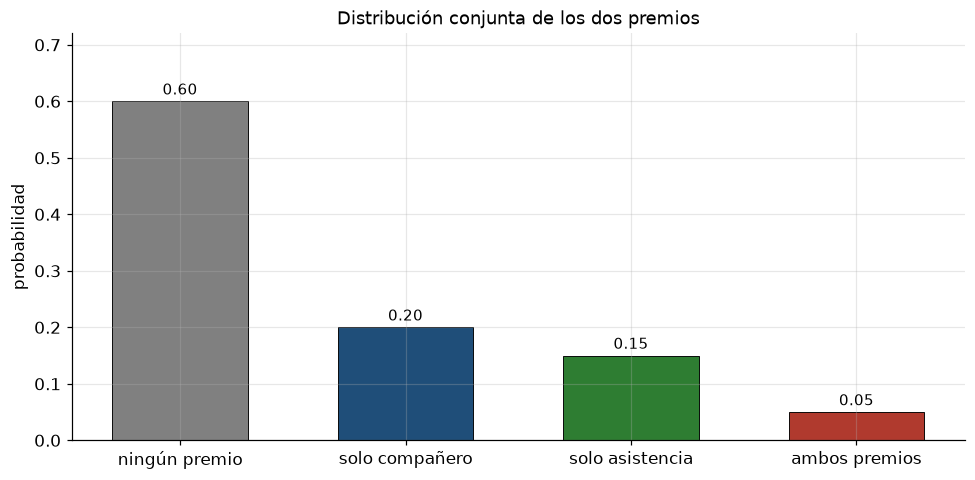

In [25]:
categorias = ["ningún premio", "solo compañero", "solo asistencia", "ambos premios"]
valores3 = [P_ninguno, P_solo_c, P_solo_r, P_ambos]
colores3 = [GRIS, AZUL, VERDE, ROJO]

fig, ax = plt.subplots()
ax.bar(categorias, valores3, width=0.6, color=colores3, edgecolor="black", linewidth=0.6)
for i, v in enumerate(valores3):
    ax.text(i, v + 0.012, f"{v:.2f}", ha="center", fontsize=10)
ax.set_ylabel("probabilidad")
ax.set_ylim(0, 0.72)
ax.set_title("Distribución conjunta de los dos premios")
plt.tight_layout()
plt.show()

## 4. Proveedores de envases de vidrio

Se denota $V_A$ y $V_B$ a la pertenencia al proveedor $A$ y al proveedor $B$, y $D$ al evento
"envase defectuoso". Datos:

$$P(V_A) = 0.20, \qquad P(V_B) = 0.80, \qquad P(D|V_A) = 0.04, \qquad P(D|V_B) = 0.02$$

$\{V_A, V_B\}$ es una partición del espacio muestral: son excluyentes, exhaustivos y ambos con
probabilidad positiva, condición que habilita la probabilidad total y Bayes.

### a) Diagrama de árbol

Primer nivel (provenencia): $P(V_A) = 0.20$ y $P(V_B) = 0.80$. Segundo nivel (calidad condicionada
a cada proveedor): $P(D|V_A) = 0.04$ con $P(D^c|V_A) = 0.96$, y $P(D|V_B) = 0.02$ con
$P(D^c|V_B) = 0.98$. El producto a lo largo de cada rama da la probabilidad conjunta de la hoja:

$$P(V_A \cap D) = 0.008, \quad P(V_A \cap D^c) = 0.192, \quad P(V_B \cap D) = 0.016, \quad P(V_B \cap D^c) = 0.784$$

La suma de las cuatro hojas es 1, normalización de la distribución conjunta.

### b) Probabilidad de que el envase no sea defectuoso

Por la probabilidad total:

$$P(D) = P(V_A)P(D|V_A) + P(V_B)P(D|V_B) = 0.20(0.04) + 0.80(0.02) = 0.008 + 0.016 = 0.024$$

$$P(D^c) = 1 - P(D) = 1 - 0.024 = 0.976$$

### c) Provenencia de un envase defectuoso

Aplicando el teorema de Bayes sobre la partición de proveedores:

$$P(V_A|D) = \frac{P(V_A)\,P(D|V_A)}{P(D)} = \frac{0.008}{0.024} = \frac{1}{3} \approx 0.3333$$

El proveedor $A$ aporta solo el 20% de los envases pero su tasa de defectos es el doble que la del
proveedor $B$, y esa evidencia eleva su participación entre los defectuosos a un tercio.

Supuestos: selección al azar de un envase sobre el total de la bodega, clasificación correcta de
provenencia y calidad, y tasas de defecto estables dentro de cada proveedor (no se mezclan lotes de
distinta procedencia en la misma probabilidad condicional).

In [26]:
P_VA, P_VB = 0.20, 0.80
P_D_VA, P_D_VB = 0.04, 0.02

P_VA_D = P_VA * P_D_VA
P_VB_D = P_VB * P_D_VB
P_D = P_VA_D + P_VB_D
P_nD = 1 - P_D
P_VA_dado_D = P_VA_D / P_D

hojas = (P_VA_D, P_VA * (1 - P_D_VA), P_VB_D, P_VB * (1 - P_D_VB))

print(f"P(V_A y D)  = 0.20 * 0.04 = {P_VA_D:.4f}")
print(f"P(V_B y D)  = 0.80 * 0.02 = {P_VB_D:.4f}")
print(f"P(D)        = {P_D:.4f}")
print(f"P(no defectuoso) = 1 - P(D) = {P_nD:.4f}")
print(f"P(V_A|D) = {P_VA_D:.4f} / {P_D:.4f} = {P_VA_dado_D:.4f}")
print("suma de las cuatro hojas:", round(sum(hojas), 12))

P(V_A y D)  = 0.20 * 0.04 = 0.0080
P(V_B y D)  = 0.80 * 0.02 = 0.0160
P(D)        = 0.0240
P(no defectuoso) = 1 - P(D) = 0.9760
P(V_A|D) = 0.0080 / 0.0240 = 0.3333
suma de las cuatro hojas: 1.0


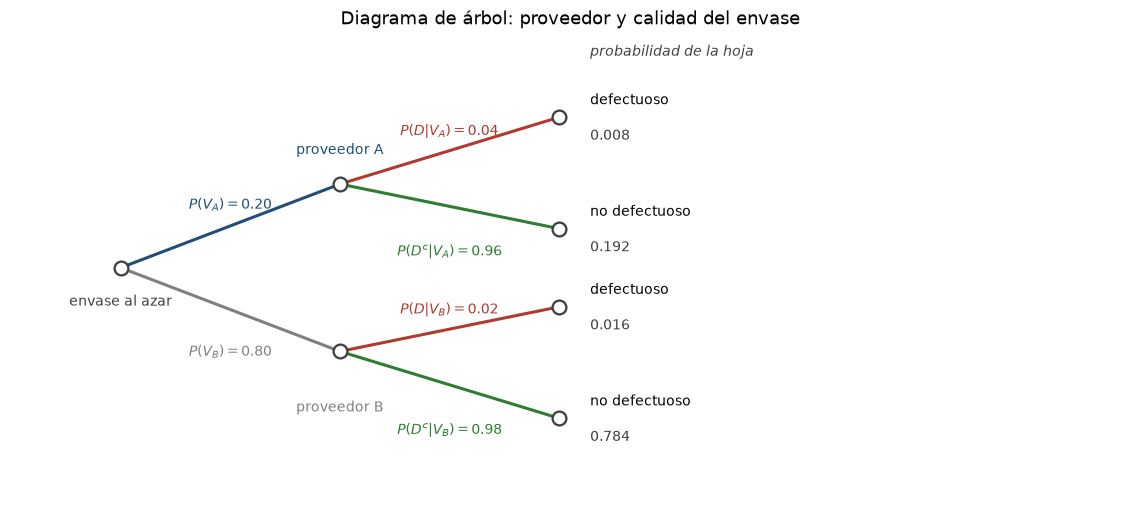

In [27]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.axis("off")
ax.set_xlim(-0.5, 4.6)
ax.set_ylim(-2.1, 2.1)


def rama(x0, y0, x1, y1, etiqueta, color, dy=0.14, va="bottom"):
    ax.plot([x0, x1], [y0, y1], color=color, linewidth=2, zorder=1)
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + dy, etiqueta, fontsize=9, color=color,
            ha="center", va=va)


def nodo(x, y):
    ax.plot(x, y, "o", markersize=9, color="white", markeredgecolor="#404040",
            markeredgewidth=1.5, zorder=3)


nodo(0, 0)
nodo(1, 0.75)
nodo(1, -0.75)
rama(0, 0, 1, 0.75, r"$P(V_A) = 0.20$", AZUL, dy=0.12)
rama(0, 0, 1, -0.75, r"$P(V_B) = 0.80$", GRIS, dy=-0.32, va="top")

for y in (1.35, 0.35, -0.35, -1.35):
    nodo(2, y)
rama(1, 0.75, 2, 1.35, r"$P(D|V_A) = 0.04$", ROJO, dy=0.10)
rama(1, 0.75, 2, 0.35, r"$P(D^c|V_A) = 0.96$", VERDE, dy=-0.34, va="top")
rama(1, -0.75, 2, -0.35, r"$P(D|V_B) = 0.02$", ROJO, dy=0.10)
rama(1, -0.75, 2, -1.35, r"$P(D^c|V_B) = 0.98$", VERDE, dy=-0.34, va="top")

hojas_tree = [
    (1.35, "defectuoso", hojas[0]),
    (0.35, "no defectuoso", hojas[1]),
    (-0.35, "defectuoso", hojas[2]),
    (-1.35, "no defectuoso", hojas[3]),
]
for y, estado, valor in hojas_tree:
    ax.text(2.14, y + 0.15, estado, fontsize=9, va="center")
    ax.text(2.14, y - 0.17, f"{valor:.3f}", fontsize=9, va="center", color="#404040")

ax.text(0, -0.34, "envase al azar", fontsize=9, ha="center", color="#404040")
ax.text(1, 0.99, "proveedor A", fontsize=9, ha="center", color=AZUL, va="bottom")
ax.text(1, -1.19, "proveedor B", fontsize=9, ha="center", color=GRIS, va="top")
ax.text(2.14, 1.9, "probabilidad de la hoja", fontsize=9, ha="left",
        color="#404040", style="italic")
ax.set_title("Diagrama de árbol: proveedor y calidad del envase")
plt.tight_layout()
plt.show()

In [28]:
# verificación por simulación de los resultados de b) y c)
rng = np.random.default_rng(21)
n_sim = 100_000

es_A = rng.random(n_sim) < P_VA
defectuoso = rng.random(n_sim) < np.where(es_A, P_D_VA, P_D_VB)

p_nD_sim = (~defectuoso).mean()
p_A_D_sim = (es_A & defectuoso).sum() / defectuoso.sum()

print("P(no defectuoso) teórica 0.9760 | simulada", round(p_nD_sim, 4))
print("P(V_A|D)         teórica 0.3333 | simulada", round(p_A_D_sim, 4))

P(no defectuoso) teórica 0.9760 | simulada 0.9752
P(V_A|D)         teórica 0.3333 | simulada 0.334


## 5. Siniestralidad de conductores

Se denota $G_1$ (buenos), $G_2$ (riesgo medio) y $G_3$ (malos) a la clase de conductor, y $S$ al
evento "accidente". Las proporciones de solicitantes dan las probabilidades previas:

$$P(G_1) = 0.30, \qquad P(G_2) = 0.50, \qquad P(G_3) = 0.20$$

y las tasas de accidente por clase:

$$P(S|G_1) = 0.01, \qquad P(S|G_2) = 0.03, \qquad P(S|G_3) = 0.10$$

$\{G_1, G_2, G_3\}$ es una partición de la población asegurada: excluyente, exhaustiva y con todas
las probabilidades positivas.

### a) Probabilidad de que el asegurado tenga un accidente

Por la regla de la probabilidad total:

$$P(S) = \sum_{i=1}^{3} P(G_i)\,P(S|G_i) = 0.30(0.01) + 0.50(0.03) + 0.20(0.10) = 0.003 + 0.015 + 0.020 = 0.038$$

### b) Clase del conductor si ocurrió un accidente

Por el teorema de Bayes:

$$P(G_1|S) = \frac{P(G_1)\,P(S|G_1)}{P(S)} = \frac{0.003}{0.038} = \frac{3}{38} \approx 0.0789$$

Completando la partición: $P(G_2|S) = 0.015/0.038 \approx 0.3947$ y
$P(G_3|S) = 0.020/0.038 \approx 0.5263$; la suma es 1, como exige la normalización de Bayes. La
clase de malos conductores, que es minoría entre los solicitantes (20%), pasa a ser la mayoría de
los siniestros: el accidente es evidencia que desplaza la distribución previa.

Supuestos: las proporciones por clase son probabilidades previas sobre la misma población, las
tasas de accidente son condicionales estables por clase, cada asegurado pertenece a exactamente una
clase y $P(S) > 0$.

In [29]:
previas = np.array([0.30, 0.50, 0.20])
tasa = np.array([0.01, 0.03, 0.10])
clases = ("buenos", "riesgo medio", "malos")

conjuntas = previas * tasa
P_S = conjuntas.sum()
posterior = conjuntas / P_S

print("contribuciones a la probabilidad total:")
for c, p, t, j in zip(clases, previas, tasa, conjuntas):
    print(f"  {c:<12} {p:.2f} * {t:.2f} = {j:.4f}")
print(f"P(accidente) = {P_S:.4f}")

print("\nposteriores P(clase|accidente):")
for c, post in zip(clases, posterior):
    print(f"  {c:<12} {post:.4f}")
print("suma de posteriores:", round(posterior.sum(), 12))

contribuciones a la probabilidad total:
  buenos       0.30 * 0.01 = 0.0030
  riesgo medio 0.50 * 0.03 = 0.0150
  malos        0.20 * 0.10 = 0.0200
P(accidente) = 0.0380

posteriores P(clase|accidente):
  buenos       0.0789
  riesgo medio 0.3947
  malos        0.5263
suma de posteriores: 1.0


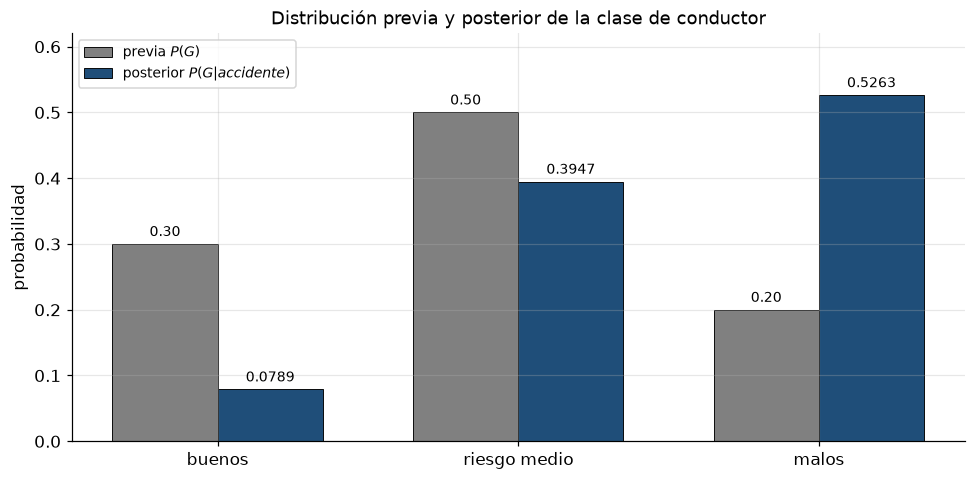

In [30]:
x = np.arange(len(clases))
ancho = 0.35

fig, ax = plt.subplots()
ax.bar(x - ancho / 2, previas, width=ancho, color=GRIS, edgecolor="black", linewidth=0.6,
       label=r"previa $P(G)$")
ax.bar(x + ancho / 2, posterior, width=ancho, color=AZUL, edgecolor="black", linewidth=0.6,
       label=r"posterior $P(G|accidente)$")
for i in range(len(clases)):
    ax.text(x[i] - ancho / 2, previas[i] + 0.012, f"{previas[i]:.2f}", ha="center", fontsize=9)
    ax.text(x[i] + ancho / 2, posterior[i] + 0.012, f"{posterior[i]:.4f}", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(clases)
ax.set_ylabel("probabilidad")
ax.set_ylim(0, 0.62)
ax.set_title("Distribución previa y posterior de la clase de conductor")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6. Huelga de pilotos y choferes

Se denota $P$ al evento "huelga de pilotos" y $C$ al evento "huelga de choferes". Datos:

$$P(P) = 0.75, \qquad P(C) = 0.65, \qquad P(P|C) = 0.90$$

### a) Probabilidad de que ambos grupos hagan huelga

Por la regla multiplicativa con el condicionamiento dado:

$$P(P \cap C) = P(C)\,P(P|C) = 0.65 \cdot 0.90 = 0.585$$

### b) Choferes dado que los pilotos hacen huelga

$$P(C|P) = \frac{P(P \cap C)}{P(P)} = \frac{0.585}{0.75} = 0.78$$

### Dependencia entre los eventos

$P(P|C) = 0.90 \ne P(P) = 0.75$: la huelga de los choferes incrementa la probabilidad de huelga de
los pilotos, y del mismo modo $P(C|P) = 0.78 \ne P(C) = 0.65$. Los eventos son dependientes; la
probabilidad conjunta $0.585$ es mayor que el producto de las marginales
($0.75 \cdot 0.65 = 0.4875$), lo que indica asociación positiva. Como referencia, la probabilidad
de huelga en al menos uno de los grupos es

$$P(P \cup C) = P(P) + P(C) - P(P \cap C) = 0.75 + 0.65 - 0.585 = 0.815$$

Supuestos: todas las probabilidades se refieren al mismo horizonte temporal y a los mismos grupos,
$P(C) > 0$ y $P(P) > 0$ para que el condicionamiento esté definido, y la información condicional
proviene de la misma fuente que las marginales (estimaciones de fuentes independientes podrían ser
inconsistentes entre sí).

In [31]:
P_P = 0.75
P_C6 = 0.65
P_P_dado_C = 0.90

P_PyC = P_C6 * P_P_dado_C
P_C_dado_P = P_PyC / P_P
P_union6 = P_P + P_C6 - P_PyC

print(f"a) P(pilotos y choferes) = {P_C6:.2f} * {P_P_dado_C:.2f} = {P_PyC:.4f}")
print(f"b) P(choferes|pilotos)  = {P_PyC:.4f} / {P_P:.4f} = {P_C_dado_P:.4f}")
print(f"P(al menos una huelga)  = {P_union6:.4f}")
print(f"producto de las marginales = {P_P * P_C6:.4f} (distinto de {P_PyC:.4f})")
print("dependientes:", not math.isclose(P_P_dado_C, P_P))

a) P(pilotos y choferes) = 0.65 * 0.90 = 0.5850
b) P(choferes|pilotos)  = 0.5850 / 0.7500 = 0.7800
P(al menos una huelga)  = 0.8150
producto de las marginales = 0.4875 (distinto de 0.5850)
dependientes: True


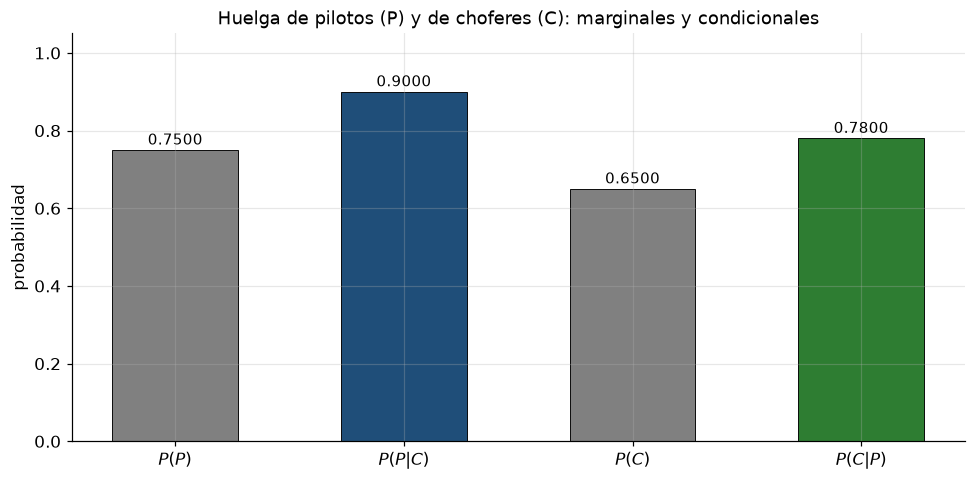

In [32]:
etiquetas6 = [r"$P(P)$", r"$P(P|C)$", r"$P(C)$", r"$P(C|P)$"]
valores6 = [P_P, P_P_dado_C, P_C6, P_C_dado_P]
colores6 = [GRIS, AZUL, GRIS, VERDE]

fig, ax = plt.subplots()
ax.bar(range(4), valores6, width=0.55, color=colores6, edgecolor="black", linewidth=0.6)
for i, v in enumerate(valores6):
    ax.text(i, v + 0.014, f"{v:.4f}", ha="center", fontsize=10)
ax.set_xticks(range(4))
ax.set_xticklabels(etiquetas6, fontsize=11)
ax.set_ylabel("probabilidad")
ax.set_ylim(0, 1.05)
ax.set_title("Huelga de pilotos (P) y de choferes (C): marginales y condicionales")
plt.tight_layout()
plt.show()

## Notas de validación

- Las secciones 4 y 5 aplican la regla de la probabilidad total y el teorema de Bayes sobre
  particiones del espacio muestral; en ambos casos la suma de las probabilidades posteriores de la
  partición es 1, verificada en la salida correspondiente.
- La sección 3 separa exclusión mutua de independencia: aquí los eventos no son excluyentes
  (intersección con probabilidad 0.05) y a la vez resultan independientes por la igualdad
  $P(C)\,P(R) = P(C \cap R)$. Recuerda que eventos excluyentes con probabilidad positiva nunca pueden
  ser independientes.
- La sección 6 muestra lo contrario: eventos con intersección no nula que resultan dependientes,
  porque $P(P|C) \ne P(P)$ y la probabilidad conjunta supera el producto de las marginales.
- Las simulaciones Monte Carlo (secciones 1 y 4) usan semilla fija para ser reproducibles y
  convergen al valor teórico con un error del orden de $1/\sqrt{M}$, siendo $M$ el número de
  ensayos.
- Supuestos comunes: todas las probabilidades de un ejercicio se refieren a la misma población y al
  mismo horizonte, los eventos de cada partición son excluyentes y exhaustivos, y toda probabilidad
  condicional se evalúa sobre un evento de referencia con probabilidad estrictamente positiva.

Referencias: Ross, S. - Probabilidad y estadística para ingeniería y ciencias. Meyer, P. -
Probabilidad y aplicaciones estadísticas. Walpole, R., Myers, R., Myers, S. - Probabilidad y
estadística para ingeniería y ciencias.